In [11]:
import os

import torch
import torch.nn.functional as F

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from scipy import stats

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

import random

from datasets import load_from_disk
from torch.utils.data import DataLoader

from src.utils.img_encoder import ImgEncoder
from src.utils.expr_encoder import ExprEncoder
from src.utils.loss_function import contrastive_loss
from src.utils.dataset_class import Multi_Modal_Dataset

from src.utils.config import PROJECT_DIR

import optuna

# import matplotlib.pyplot as plt

In [12]:
checkpoint_path = os.path.join(PROJECT_DIR, "checkpoints", "best-epoch=68-val_loss=4.0644.ckpt")
checkpoint = torch.load(checkpoint_path, map_location="cpu")
hparams = checkpoint['hyper_parameters']

expr_encoder = ExprEncoder(
    in_dim=2000,
    hidden_dims=hparams['expr_hidden_dims'],
    out_dim=128,
    dropout_probs=hparams['expr_dropout_probs'],
    batchnorm=True # [*]
)

img_encoder = ImgEncoder(
    in_dim=2048,
    hidden_dims=hparams['img_hidden_dims'],
    out_dim=128,
    dropout_probs=hparams['img_dropout_probs'],
    batchnorm=True # [*]
)

state_dict = checkpoint['state_dict']

img_state_dict = {k.replace('img_encoder.', ''): v for k, v in state_dict.items() if k.startswith('img_encoder.')}
expr_state_dict = {k.replace('expr_encoder.', ''): v for k, v in state_dict.items() if k.startswith('expr_encoder.')}

# Load into models
img_encoder.load_state_dict(img_state_dict)
expr_encoder.load_state_dict(expr_state_dict)

img_encoder.eval()
expr_encoder.eval()

# def (img, expr, pid):
#     return img_encoder(img), expr_encoder(expr), pid
    
print("Encoder weights loaded successfully!")

Encoder weights loaded successfully!


In [13]:
arrow_dataset = load_from_disk(os.path.join(PROJECT_DIR, "data", "dataset"))
all_data = {}
with torch.no_grad():
    for k in ['train', 'valid', 'test']:
        img, expr, pid = next(iter(DataLoader(
            Multi_Modal_Dataset(arrow_dataset[k], k_patches="all"),
            batch_size=len(arrow_dataset[k])
        )))
        all_data[k+'_img'] = img
        all_data[k+'_expr'] = expr
        all_data[k+'_img_emb'] = img_encoder(img)
        all_data[k+'_expr_emb'] = expr_encoder(expr)
        all_data[k+'_pid'] = [p[:12] for p in pid]

for x in ['_img', '_expr']:
    for y in ['', '_emb']:
        all_data['dev'+x+y] = torch.cat((all_data['train'+x+y], all_data['valid'+x+y]), dim=0)
all_data['dev_pid'] = all_data['train_pid'] + all_data['valid_pid']

sims = F.cosine_similarity(
    all_data['test_img_emb'].unsqueeze(1), 
    all_data['dev_expr_emb'].unsqueeze(0),   # dev_img_emb
    dim=2
)


# sanity check!
for i in range(all_data['test_img_emb'].shape[0]):
    for j in range(all_data['dev_expr_emb'].shape[0]):    # dev_img_emb
        assert abs(sims[i, j].item() - torch.matmul(
            F.normalize(all_data['test_img_emb'][i].unsqueeze(0), dim=1), 
            F.normalize(all_data['dev_expr_emb'][j].unsqueeze(0), dim=1).T      # dev_img_emb
        ).item()) < 1e-6

sorted_sims = torch.argsort(sims, dim=1, descending=True)

pid_mapping = {
    all_data['test_pid'][i]: [all_data['dev_pid'][j] for j in row.tolist()]
    for i, row in enumerate(sorted_sims)
}

print('Done')

Done


In [85]:
clin_df = pd.read_csv(os.path.join(PROJECT_DIR, "data", "data_clinical_patient.txt"), sep='\t', header=None)
clin_df.columns = clin_df.iloc[4].values
clin_df = clin_df.iloc[5:].reset_index(drop=True)
clin_df['SUBTYPE'] = clin_df['SUBTYPE'].str.replace('BRCA_', '', regex=False)
pid2subtype = clin_df.set_index('PATIENT_ID')['SUBTYPE'].to_dict()

def zero_shot_subtype_classification(K):
    
    knn_subtypes = { 
        k: [pid2subtype[k]] + [pid2subtype[p] for p in v if pd.notna(pid2subtype[p])]
        for k, v in pid_mapping.items()
    }
    knn_subtypes = pd.DataFrame(knn_subtypes)
    knn_subtypes = knn_subtypes.dropna(axis=1, how='any')
    knn_subtypes = knn_subtypes.iloc[:(K+1)]

    def get_strict_majority(col):
        # 1. Get the frequency counts
        counts = col.value_counts()
        
        assert not counts.empty
        
        # 2. If there's only one unique value, it's the majority
        if len(counts) == 1:
            return counts.index[0]
        
        # 3. Compare the count of the 1st most frequent to the 2nd
        # If the 1st frequency is strictly greater than the 2nd, we have a winner
        if counts.iloc[0] > counts.iloc[1]:
            return counts.index[0]
        
        # 4. Otherwise, it's a tie (e.g., [a, b, c, b, a, c] or [a, a, b, b])
        return 'Unclassified'

    vote_subtypes = pd.concat(
        [knn_subtypes.iloc[:1], knn_subtypes.iloc[1:].agg([get_strict_majority])], 
        axis=0
    ).reset_index(drop=True)

    y_true = vote_subtypes.iloc[0].tolist()
    y_pred = vote_subtypes.iloc[1].tolist()
    
    return y_true, y_pred


print('Done')

Done


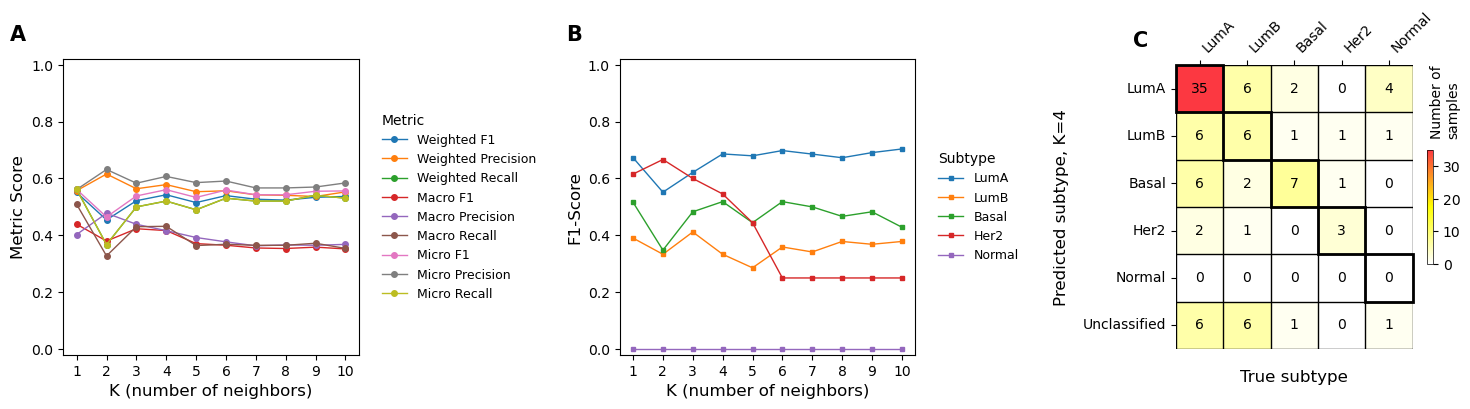

In [252]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from sklearn.metrics import classification_report, confusion_matrix

# ==========================================
# 0. GLOBAL CONFIGURATION & FONT SIZES
# ==========================================
K_TARGET = 4

# Centralized Font Variables
AXIS_TITLE_SIZE = 12
AXIS_TICK_SIZE = 10
LEGEND_TITLE_SIZE = 10
LEGEND_TEXT_SIZE = 9

# Panel label adjustments (A, B, C positions relative to axis)
PANEL_X = -0.18
PANEL_Y = 1.05
PANEL_SIZE = 15


# ==========================================
# 1. DATA GENERATION & EXTRACTION PIPELINE
# ==========================================
target_labels = ['LumA', 'LumB', 'Basal', 'Her2', 'Normal']
k_values = list(range(1, 11))

metrics = {
    'Weighted F1': [], 'Weighted Precision': [], 'Weighted Recall': [],
    'Macro F1': [], 'Macro Precision': [], 'Macro Recall': [],
    'Micro F1': [], 'Micro Precision': [], 'Micro Recall': []
}
class_f1_scores = {label: [] for label in target_labels}

cm_y_true, cm_y_pred = None, None

for k in k_values:
    y_true, y_pred = zero_shot_subtype_classification(k)
    
    if k == K_TARGET:
        cm_y_true, cm_y_pred = y_true, y_pred
        
    report_dict = classification_report(
        y_true, y_pred, 
        labels=target_labels, 
        zero_division=0, 
        output_dict=True
    )
    
    if 'micro avg' in report_dict:
        micro_row = report_dict['micro avg']
    else:
        acc_val = report_dict['accuracy']
        micro_row = {'precision': acc_val, 'recall': acc_val, 'f1-score': acc_val}

    macro_row = report_dict['macro avg']
    weighted_row = report_dict['weighted avg']
    
    metrics['Weighted F1'].append(weighted_row['f1-score'])
    metrics['Weighted Precision'].append(weighted_row['precision'])
    metrics['Weighted Recall'].append(weighted_row['recall'])
    metrics['Macro F1'].append(macro_row['f1-score'])
    metrics['Macro Precision'].append(macro_row['precision'])
    metrics['Macro Recall'].append(macro_row['recall'])
    metrics['Micro F1'].append(micro_row['f1-score'])
    metrics['Micro Precision'].append(micro_row['precision']) 
    metrics['Micro Recall'].append(micro_row['recall'])
    
    for label in target_labels:
        class_f1_scores[label].append(report_dict[label]['f1-score'])


# ==========================================
# 2. CONFUSION MATRIX MATH
# ==========================================
cm_true_labels = ['LumA', 'LumB', 'Basal', 'Her2', 'Normal']
cm_pred_labels = ['LumA', 'LumB', 'Basal', 'Her2', 'Normal', 'Unclassified']
cm_all_labels = ['LumA', 'LumB', 'Basal', 'Her2', 'Normal', 'Unclassified']

cm_raw = confusion_matrix(cm_y_true, cm_y_pred, labels=cm_all_labels)
cm_sliced = cm_raw[:5, :]
cm_final = cm_sliced.T


# ==========================================
# 3. UNIFIED VISUALIZATION SETUP (1x3)
# ==========================================
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 6))

# ------------------------------------------
# PLOT 1 (LEFT): Global Metrics
# ------------------------------------------
ax1.text(PANEL_X, PANEL_Y, 'A', transform=ax1.transAxes, fontsize=PANEL_SIZE, va='bottom', ha='left', fontweight='bold')

for metric_name, values in metrics.items():
    ax1.plot(k_values, values, marker='o', linewidth=1, markersize=4, label=metric_name)

ax1.set_xlabel('K (number of neighbors)', fontsize=AXIS_TITLE_SIZE)
ax1.set_ylabel('Metric Score', fontsize=AXIS_TITLE_SIZE)
ax1.set_xticks(k_values)
ax1.tick_params(axis='both', labelsize=AXIS_TICK_SIZE)
ax1.set_ylim(-0.02, 1.02)
ax1.legend(bbox_to_anchor=(1.04, 0.5), title='Metric', alignment='left',
           loc="center left", frameon=False, fontsize=LEGEND_TEXT_SIZE)
ax1.set_box_aspect(1)


# ------------------------------------------
# PLOT 2 (MIDDLE): Individual Class F1-Scores
# ------------------------------------------
ax2.text(PANEL_X, PANEL_Y, 'B', transform=ax2.transAxes, fontsize=PANEL_SIZE, va='bottom', ha='left', fontweight='bold')

for label in target_labels:
    ax2.plot(k_values, class_f1_scores[label], marker='s', linewidth=1, markersize=3, label=label)

ax2.set_xlabel('K (number of neighbors)', fontsize=AXIS_TITLE_SIZE)
ax2.set_ylabel('F1-Score', fontsize=AXIS_TITLE_SIZE)
ax2.set_xticks(k_values)
ax2.tick_params(axis='both', labelsize=AXIS_TICK_SIZE)
ax2.set_ylim(-0.02, 1.02)
ax2.legend(bbox_to_anchor=(1.04, 0.5), title='Subtype', alignment='left',
           loc="center left", frameon=False, fontsize=LEGEND_TEXT_SIZE)
ax2.set_box_aspect(1)


# ------------------------------------------
# PLOT 3 (RIGHT): Confusion Matrix
# ------------------------------------------
ax3.text(PANEL_X, PANEL_Y, 'C', transform=ax3.transAxes, fontsize=PANEL_SIZE, va='bottom', ha='left', fontweight='bold')

custom_colors = ['#ffffff', 'yellow', '#fc3841'] 
custom_cmap = LinearSegmentedColormap.from_list('white_yellow_red', custom_colors)

sns.heatmap(
    cm_final, 
    annot=False,             
    cmap=custom_cmap,            
    xticklabels=cm_true_labels, 
    yticklabels=cm_pred_labels, 
    cbar=True,               
    square=True,
    cbar_kws={'shrink': 0.2}, 
    ax=ax3
)

# Colorbar adjustments
cbar = ax3.collections[0].colorbar
cbar.ax.set_title('Number of\nsamples', rotation=90, ha='left', #va='bottom',
                  fontsize=LEGEND_TITLE_SIZE, pad=10, loc='center')
cbar.ax.tick_params(labelsize=AXIS_TICK_SIZE)
cbar.outline.set_visible(True)
cbar.outline.set_edgecolor('black')
cbar.outline.set_linewidth(0.5)

# Cell value rendering
num_rows, num_cols = cm_final.shape
for row in range(num_rows):
    for col in range(num_cols):
        value = cm_final[row, col]
        is_diagonal = (row == col and row < 5)
        
        ax3.text(col + 0.5, row + 0.5, str(value), ha='center', va='center', fontsize=AXIS_TICK_SIZE)
        
        if is_diagonal:
            rect = Rectangle((col, row), 1, 1, fill=False, edgecolor='black', linewidth=2, clip_on=False)
            ax3.add_patch(rect)

# Axis layout configuration
ax3.xaxis.tick_top()
ax3.set_xticklabels(cm_true_labels, rotation=45, ha='left', fontsize=AXIS_TICK_SIZE)
ax3.set_yticklabels(cm_pred_labels, rotation=0, ha='right', fontsize=AXIS_TICK_SIZE)
ax3.set_xlabel('True subtype', fontsize=AXIS_TITLE_SIZE, labelpad=15)
ax3.set_ylabel('Predicted subtype, K=' + str(K_TARGET), fontsize=AXIS_TITLE_SIZE, labelpad=10)

ax3.hlines(range(0, num_rows+1), *ax3.get_xlim(), colors='black', linewidth=1)
ax3.vlines(range(0, num_cols+1), *ax3.get_ylim(), colors='black', linewidth=1)

# ==========================================
# 4. DEPLOY WINDOW
# ==========================================
plt.tight_layout()
plt.savefig("classification.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [86]:
# ------------------------------------------------------------------------------------------------------------------
print("Preprocess gene expression data")

expr_all = pd.read_csv(os.path.join(PROJECT_DIR, "data", "data_mrna_seq_v2_rsem.txt"), sep="\t")

assert expr_all.shape[1] == len(set(expr_all.columns))
genes_all = expr_all.iloc[:, :2].copy()
expr_all = expr_all.iloc[:, 2:].copy()
expr_all.columns = [col[:12] for col in expr_all.columns]
assert expr_all.notna().all().all()

# Select top 2000 most variable genes 
# Note that the variance calculation is done within the train data
columns_in_train = list(set(expr_all.columns) & set(all_data['train_pid']))
variances = expr_all[columns_in_train].var(axis=1)
index_top2000 = variances.sort_values(ascending=False).head(2000).index
expr_top2000 = expr_all.loc[index_top2000]
genes_top2000 = genes_all.loc[index_top2000]

# log1p-transformation
expr_top2000_log1p = np.log1p(expr_top2000)


print('Done')

Preprocess gene expression data
Done


In [64]:
expr_top2000_log1p_retr_k10 = pd.DataFrame({
    k: expr_top2000_log1p[[x for x in v if x in expr_top2000_log1p.columns][:10]].median(axis=1)
    for k, v in pid_mapping.items() 
    if k in expr_top2000_log1p.columns
})

expr_top2000_log1p_retr_k1 = pd.DataFrame({
    k: expr_top2000_log1p[[x for x in v if x in expr_top2000_log1p.columns][:1]].median(axis=1)
    for k, v in pid_mapping.items() 
    if k in expr_top2000_log1p.columns
})

random.seed(456)
expr_top2000_log1p_retr_rand = pd.DataFrame({
    k: expr_top2000_log1p[random.sample(all_data['dev_pid'], 10)].median(axis=1)
    for k in pid_mapping.keys() 
    if k in expr_top2000_log1p.columns
})

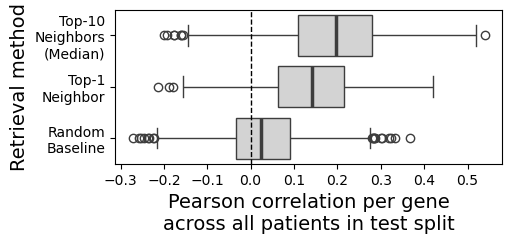

0.19602325754820443
0.02486265112837123


In [219]:
m_k10 = expr_top2000_log1p_retr_k10.corrwith(expr_top2000_log1p[expr_top2000_log1p_retr_k10.columns], axis=1, method='pearson')
m_k1 = expr_top2000_log1p_retr_k1.corrwith(expr_top2000_log1p[expr_top2000_log1p_retr_k1.columns], axis=1, method='pearson')
m_r = expr_top2000_log1p_retr_rand.corrwith(expr_top2000_log1p[expr_top2000_log1p_retr_rand.columns], axis=1, method='pearson')

plt.figure(figsize=(5, 2))
sns.boxplot(
    data=pd.DataFrame({
        'Top-10\nNeighbors\n(Median)': m_k10,
        'Top-1\nNeighbor': m_k1,
        'Random\nBaseline': m_r
    }), 
    color='lightgrey', 
    orient="h",
    medianprops={'linewidth': 2.5}
)
plt.axvline(x=0, color='black', linestyle='--', linewidth=1, zorder=3)
plt.xlabel('Pearson correlation per gene\nacross all patients in test split', fontsize=14)
plt.ylabel('Retrieval method', fontsize=14)
plt.savefig('corr.pdf', format='pdf', bbox_inches='tight')
plt.show()

print(m_k10.median())
print(m_r.median())

In [220]:
import gseapy as gp

expr = expr_all
expr.index = genes_all['Hugo_Symbol'].to_list()
expr = expr[expr.index.notna()]

retrieved_expr = pd.DataFrame({
    k: expr[[x for x in v if x in expr.columns][:10]].median(axis=1)
    for k, v in pid_mapping.items() 
    if k in expr.columns
})

ground_truth_exp = expr[pid_mapping.keys()]

gene_sets = os.path.join(PROJECT_DIR, "data", "MSigDB_H.gmt")

def compute_ssgsea(expr_df, gene_sets):
    ss = gp.ssgsea(
        data=expr_df,   # gseapy expects genes × samples
        gene_sets=gene_sets,
        sample_norm_method='rank',
        outdir=None,   # do not write files
        no_plot=True
    )
    
    return ss.res2d

true_pathways = compute_ssgsea(ground_truth_exp, gene_sets)
true_pathways = true_pathways.pivot(
    index="Term",     # gene sets
    columns="Name",   # samples
    values="NES"      # enrichment score
)


retrieve_pathway = compute_ssgsea(retrieved_expr, gene_sets)
retrieve_pathway = retrieve_pathway.pivot(
    index="Term",     # gene sets
    columns="Name",   # samples
    values="NES"      # enrichment score
)

2026-05-21 23:49:25,518 [WARNING] Found duplicated gene names, values averaged by gene names!
2026-05-21 23:49:28,135 [WARNING] Found duplicated gene names, values averaged by gene names!


In [175]:
genes_top2000.loc[m_k10.sort_values(ascending=False).index]['Hugo_Symbol'].tolist()[:20]

['SEC14L2',
 'ELN',
 'COL14A1',
 'CCND1',
 'AGR3',
 'MMP2',
 'APBB2',
 'SERPING1',
 'COL1A2',
 'BCL2',
 'NNMT',
 'SCUBE2',
 'FBLN5',
 'THBS2',
 'CCT5',
 'MYB',
 'CCDC80',
 'CDH1',
 'OGN',
 'COL6A2']

##################
0.2662456390724848
##################


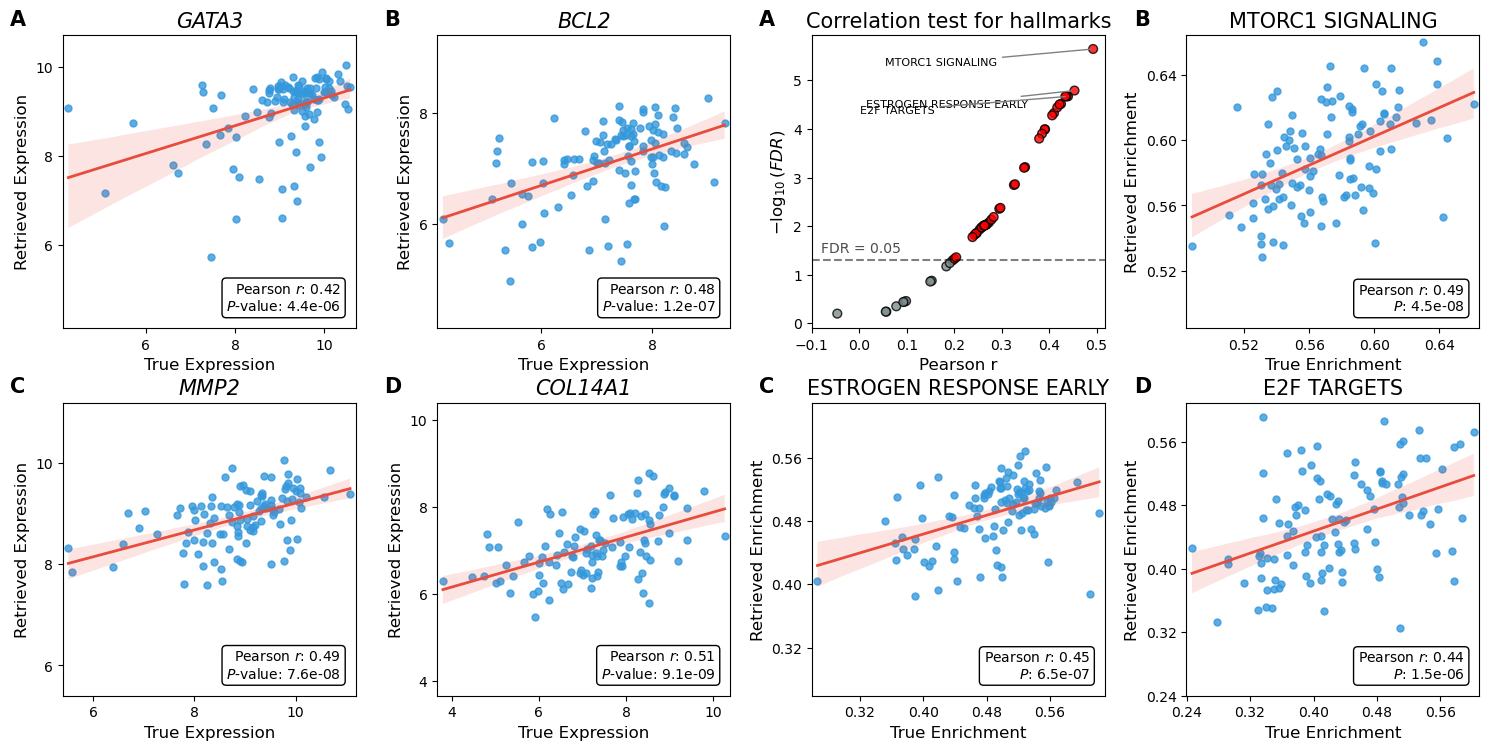

In [221]:
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import MaxNLocator
from scipy import stats
from scipy.stats import pearsonr

# =====================================================================
# GLOBAL FONT SIZE CONFIGURATION
# =====================================================================
FONT_AXIS_TICK = 10   # Size of individual tick labels (numbers on axes)
FONT_AXIS_TITLE = 12  # Size of X and Y axis titles
FONT_PLOT_TITLE = 15  # Size of main subfigure/plot titles
FONT_LABEL = 15       # Size of labels A, B, C, D

# =====================================================================
# 1. PRE-COMPUTE PATHWAY DATA (Volcano & Pathway Regressions)
# =====================================================================
corrs = []
pvals = []
for i in range(len(true_pathways)):
    c, p = pearsonr(
        true_pathways.iloc[i].tolist(), retrieve_pathway.iloc[i].tolist()
    )
    corrs.append(c)
    pvals.append(p)

print('##################', np.median(corrs), '##################', sep='\n')

selected_pathways = [
    "HALLMARK_MTORC1_SIGNALING",
    "HALLMARK_ESTROGEN_RESPONSE_EARLY",
    "HALLMARK_E2F_TARGETS",
]

pathway_indices = [
    true_pathways.index.tolist().index(p) for p in selected_pathways
]

# =====================================================================
# 2. DEFINE HELPER PLOTTING FUNCTIONS
# =====================================================================


def sctrplt(g, ax):
    """Plots True vs Retrieved Gene Expression."""
    x = np.array(
        expr_top2000_log1p[expr_top2000_log1p_retr_k10.columns].loc[
            genes_top2000.loc[genes_top2000["Hugo_Symbol"] == g].index
        ]
    ).squeeze()

    y = np.array(
        expr_top2000_log1p_retr_k10.loc[
            genes_top2000.loc[genes_top2000["Hugo_Symbol"] == g].index
        ]
    ).squeeze()

    pearson_r, pearson_p = stats.pearsonr(x, y)

    sns.regplot(
        x=x,
        y=y,
        scatter_kws={"s": 25, "alpha": 0.8, "color": "#3498db"},
        line_kws={"color": "#e74c3c", "lw": 2},
        ci=95,
        ax=ax,
    )

    all_data = np.concatenate([x, y])
    d_min, d_max = all_data.min(), all_data.max()
    d_range = d_max - d_min

    offset = d_range * 0.02
    xmin = d_min - offset
    xmax = d_max + offset
    ax_limit = [xmin, xmax]

    ax.set_xlim(ax_limit)
    ax.set_ylim(ax_limit)

    ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    ax.set_aspect("equal", adjustable="box")

    stats_label = f"Pearson $r$: {pearson_r:.2f}\n$P$-value: {pearson_p:.1e}"
    ax.text(
        0.95,
        0.05,
        stats_label,
        transform=ax.transAxes,
        fontsize=10,
        verticalalignment="bottom",
        horizontalalignment="right",
        bbox=dict(boxstyle="round", facecolor="white", alpha=1),
    )

    ax.set_title(g, fontstyle="italic", fontsize=FONT_PLOT_TITLE)
    ax.set_xlabel("True Expression", fontsize=FONT_AXIS_TITLE)
    ax.set_ylabel("Retrieved Expression", fontsize=FONT_AXIS_TITLE)
    ax.tick_params(labelsize=FONT_AXIS_TICK)


def draw_volcano_on_axis(ax, corr, pval, indices, labels):
    """Plots Volcano Plot onto a specific grid axis, matching grid box bounds."""
    fdr = stats.false_discovery_control(pval)

    corr = np.atleast_1d(corr)
    fdr = np.atleast_1d(fdr)

    neg_log_fdr = -np.log10(fdr)
    threshold = -np.log10(0.05)
    colors = ["red" if p > threshold else "#7f8c8d" for p in neg_log_fdr]

    ax.axhline(
        y=threshold, color="black", linestyle="--", alpha=0.5
    )


    ax.text(
        x=-0.08, 
        y=threshold + 0.09,        # Small positive offset pushes it above the line
        s="FDR = 0.05", 
        fontsize=10,               # Matches standard text sizes or use a custom variable
        color="black", 
        alpha=0.7,
        verticalalignment="bottom", # Anchors text alignment from its bottom boundary
        horizontalalignment="left"
    )

    ax.scatter(corr, neg_log_fdr, c=colors, alpha=0.8, edgecolors="black", s=40)

    if indices is not None and labels is not None:
        for idx, label in zip(indices, labels):
            x = corr[idx]
            y = neg_log_fdr[idx]

            ax.annotate(
                label.replace("HALLMARK_", "").replace("_", " "),
                xy=(x, y),
                xytext=(-150, -10),
                textcoords="offset points",
                fontsize=8,
                va="center",
                arrowprops=dict(arrowstyle="-", color="grey", lw=1),
            )

    ax.set_xlim([-0.1, 1.05 * max(corr)])
    ax.set_ylim([-0.1, 1.05 * max(neg_log_fdr)])

    # Enforce standard square grid dimensions exactly matching our scatter plots
    ax.set_aspect((0.1+1.05 * max(corr))/(0.1+1.05 * max(neg_log_fdr)), adjustable="box")

    ax.set_title("Correlation test for hallmarks", fontsize=FONT_PLOT_TITLE)
    ax.set_xlabel("Pearson r", fontsize=FONT_AXIS_TITLE)
    ax.set_ylabel("$-\log_{10}(FDR)$", fontsize=FONT_AXIS_TITLE)
    ax.tick_params(labelsize=FONT_AXIS_TICK)
    # ax.legend(loc="upper left")


# =====================================================================
# 3. INITIALIZE THE 2x4 GRID FIGURE
# =====================================================================
fig, axs = plt.subplots(2, 4, figsize=(18/1.2, 9/1.2))

# --- Left half: Gene Scatterplots (Columns 0 & 1) ---
sctrplt("GATA3", axs[0, 0])
sctrplt("BCL2", axs[0, 1])
sctrplt("MMP2", axs[1, 0])
sctrplt("COL14A1", axs[1, 1])

# --- Right half: Pathway Statistics (Columns 2 & 3) ---
draw_volcano_on_axis(
    axs[0, 2], corrs, pvals, pathway_indices, selected_pathways
)

pathway_axes = [axs[0, 3], axs[1, 2], axs[1, 3]]

for i, ax in enumerate(pathway_axes):
    pathway = selected_pathways[i]

    x = true_pathways.loc[pathway].astype(float).values
    y = retrieve_pathway.loc[pathway].astype(float).values

    combined_data = np.concatenate([x, y])
    data_min, data_max = combined_data.min(), combined_data.max()
    offset = (data_max - data_min) * 0.02
    axis_min, axis_max = data_min - offset, data_max + offset

    c, p = pearsonr(x, y)

    sns.regplot(
        x=x,
        y=y,
        ci=95,
        ax=ax,
        scatter_kws={"alpha": 0.8, "s": 25, "color": "#3498db"},
        line_kws={"color": "#e74c3c", "lw": 2},
    )

    stats_text = f"Pearson $r$: {c:.2f}\n$P$: {p:.1e}"
    ax.text(
        0.95,
        0.05,
        stats_text,
        transform=ax.transAxes,
        fontsize=10,
        verticalalignment="bottom",
        horizontalalignment="right",
        bbox=dict(boxstyle="round", facecolor="white", alpha=1),
    )

    ax.set_title(
        pathway.replace("HALLMARK_", "").replace("_", " "), fontsize=FONT_PLOT_TITLE
    )
    ax.set_xlabel("True Enrichment", fontsize=FONT_AXIS_TITLE)
    ax.set_ylabel("Retrieved Enrichment", fontsize=FONT_AXIS_TITLE)

    ax.set_xlim(axis_min, axis_max)
    ax.set_ylim(axis_min, axis_max)

    ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    ax.set_aspect("equal", adjustable="box")
    ax.tick_params(labelsize=FONT_AXIS_TICK)


# =====================================================================
# 4. ADD SUBFIGURE LABELS (A, B, C, D)
# =====================================================================
labels = ["A", "B", "C", "D"]

left_axes = [axs[0, 0], axs[0, 1], axs[1, 0], axs[1, 1]]
right_axes = [axs[0, 2], axs[0, 3], axs[1, 2], axs[1, 3]]

for label, l_ax, r_ax in zip(labels, left_axes, right_axes):
    l_ax.text(
        -0.18,
        1.02,
        label,
        transform=l_ax.transAxes,
        fontsize=FONT_LABEL,
        fontweight="bold",
        va="bottom",
        ha="left",
    )

    r_ax.text(
        -0.18,
        1.02,
        label,
        transform=r_ax.transAxes,
        fontsize=FONT_LABEL,
        fontweight="bold",
        va="bottom",
        ha="left",
    )

# =====================================================================
# 5. SAVE AND SHOW COMBINED GRAPH
# =====================================================================
plt.tight_layout()
plt.savefig("combined_expression_pathway_grid.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [ ]:
import pandas as pd
from scipy.stats import pearsonr
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

corrs = []
pvals = []
spearman_corrs = []
spearman_pvals = []
pvals = []
pathways = []

# Loop over pathways
for i in range(50):
    pathway = true_pathways.index[i]
    
    x = true_pathways.loc[pathway].astype(float).values
    y = retrieve_pathway.loc[pathway].astype(float).values
    
    c, p = pearsonr(x, y)
    c_spearman, p_spearman = spearmanr(x, y)
    
    pathways.append(pathway)
    corrs.append(c)
    pvals.append(p)

    spearman_corrs.append(c_spearman)
    spearman_pvals.append(p_spearman)

# FDR correction
reject, pvals_fdr, _, _ = multipletests(pvals, method='fdr_bh')
s_reject, s_pvals_fdr, _, _ = multipletests(spearman_pvals, method='fdr_bh')

# Create DataFrame
results = pd.DataFrame({
    'pathway': pathways,
    'pearson_correlation': corrs,
    'pearson_p_value': pvals,
    'pearson_FDR': pvals_fdr,
    'pearson_significant': reject,
    'spearson_correlation': spearman_corrs,
    'spearson_p_value': spearman_pvals,
    'spearman_FDR': s_pvals_fdr,
    'spearman_significant': s_reject,
    
})

# Optional: sort by FDR (most significant first)
results = results.sort_values('pearson_FDR')
results
# results.to_excel('pathway_correlation_results.xlsx', index=False)


In [ ]:
from scipy.stats import spearmanr

corrs_s = []
pvals_s = []

for i in range(len(true_pathways)):
    # Use .iloc[i] to ensure you are moving through each row
    x = true_pathways.iloc[i].astype(float).values
    y = retrieve_pathway.iloc[i].astype(float).values
    
    # Calculate Spearman
    c, p = spearmanr(x, y)
    
    corrs_s.append(c)
    pvals_s.append(p)

In [14]:
classes = ['LumA', 'LumB', 'Basal']#, 'Her2', 'Normal']

def clear_missing_data(X1, X2, X3, y, pid, classes):
    rm_indices = [i for i, v in enumerate(y) if v not in classes]
    y = [o for o in y if o in classes]
    X1 = np.delete(X1, rm_indices, axis=0)
    X2 = np.delete(X2, rm_indices, axis=0)
    pid = [pid[i] for i in range(len(pid)) if i not in rm_indices]
    return X1, X2, X3, y, pid

lrData = {
    f'{var}_{k}': val 
    for k in ['dev', 'test'] 
    for var, val in zip(['X1', 'X2', 'X3', 'y', 'pid'], clear_missing_data(
        X1 = all_data[f'{k}_img_emb'].numpy(), 
        X2 = all_data[f'{k}_img'].numpy(), 
        X3 = all_data[f'{k}_expr'].numpy(), 
        y = [pid2subtype.get(p, np.nan) for p in all_data[f'{k}_pid']], 
        pid = all_data[f'{k}_pid'], 
        classes = classes
    ))
}

# sanity check
assert lrData['X1_dev'].shape[0] == len(lrData['y_dev'])
assert lrData['X1_test'].shape[0] == len(lrData['y_test'])
assert lrData['y_dev'] == [pid2subtype[p] for p in lrData['pid_dev']]
assert lrData['y_test'] == [pid2subtype[p] for p in lrData['pid_test']]

In [ ]:
def fitLogReg(X, y):
    stratified_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=8754)
    model = LogisticRegressionCV(
        cv=stratified_cv,  
        solver='saga',      
        l1_ratios=[0.5], 
        max_iter=10000,
        random_state=42,
        use_legacy_attributes=False
    )
    model.fit(X, y)
    return model

In [ ]:
m1 = fitLogReg(lrData['X1_dev'], lrData['y_dev'])

In [716]:
report1 = classification_report(lrData['y_test'], m1.predict(lrData['X1_test']), labels=classes, zero_division=0, output_dict=True)

In [ ]:
preprocessor = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=128))
])
lrData['X2_dev_pca'] = preprocessor.fit_transform(lrData['X2_dev'])
lrData['X2_test_pca'] = preprocessor.transform(lrData['X2_test'])

m2 = fitLogReg(lrData['X2_dev_pca'], lrData['y_dev'])

In [734]:
report2 = classification_report(lrData['y_test'], m2.predict(lrData['X2_test_pca']), labels=classes, zero_division=0, output_dict=True)

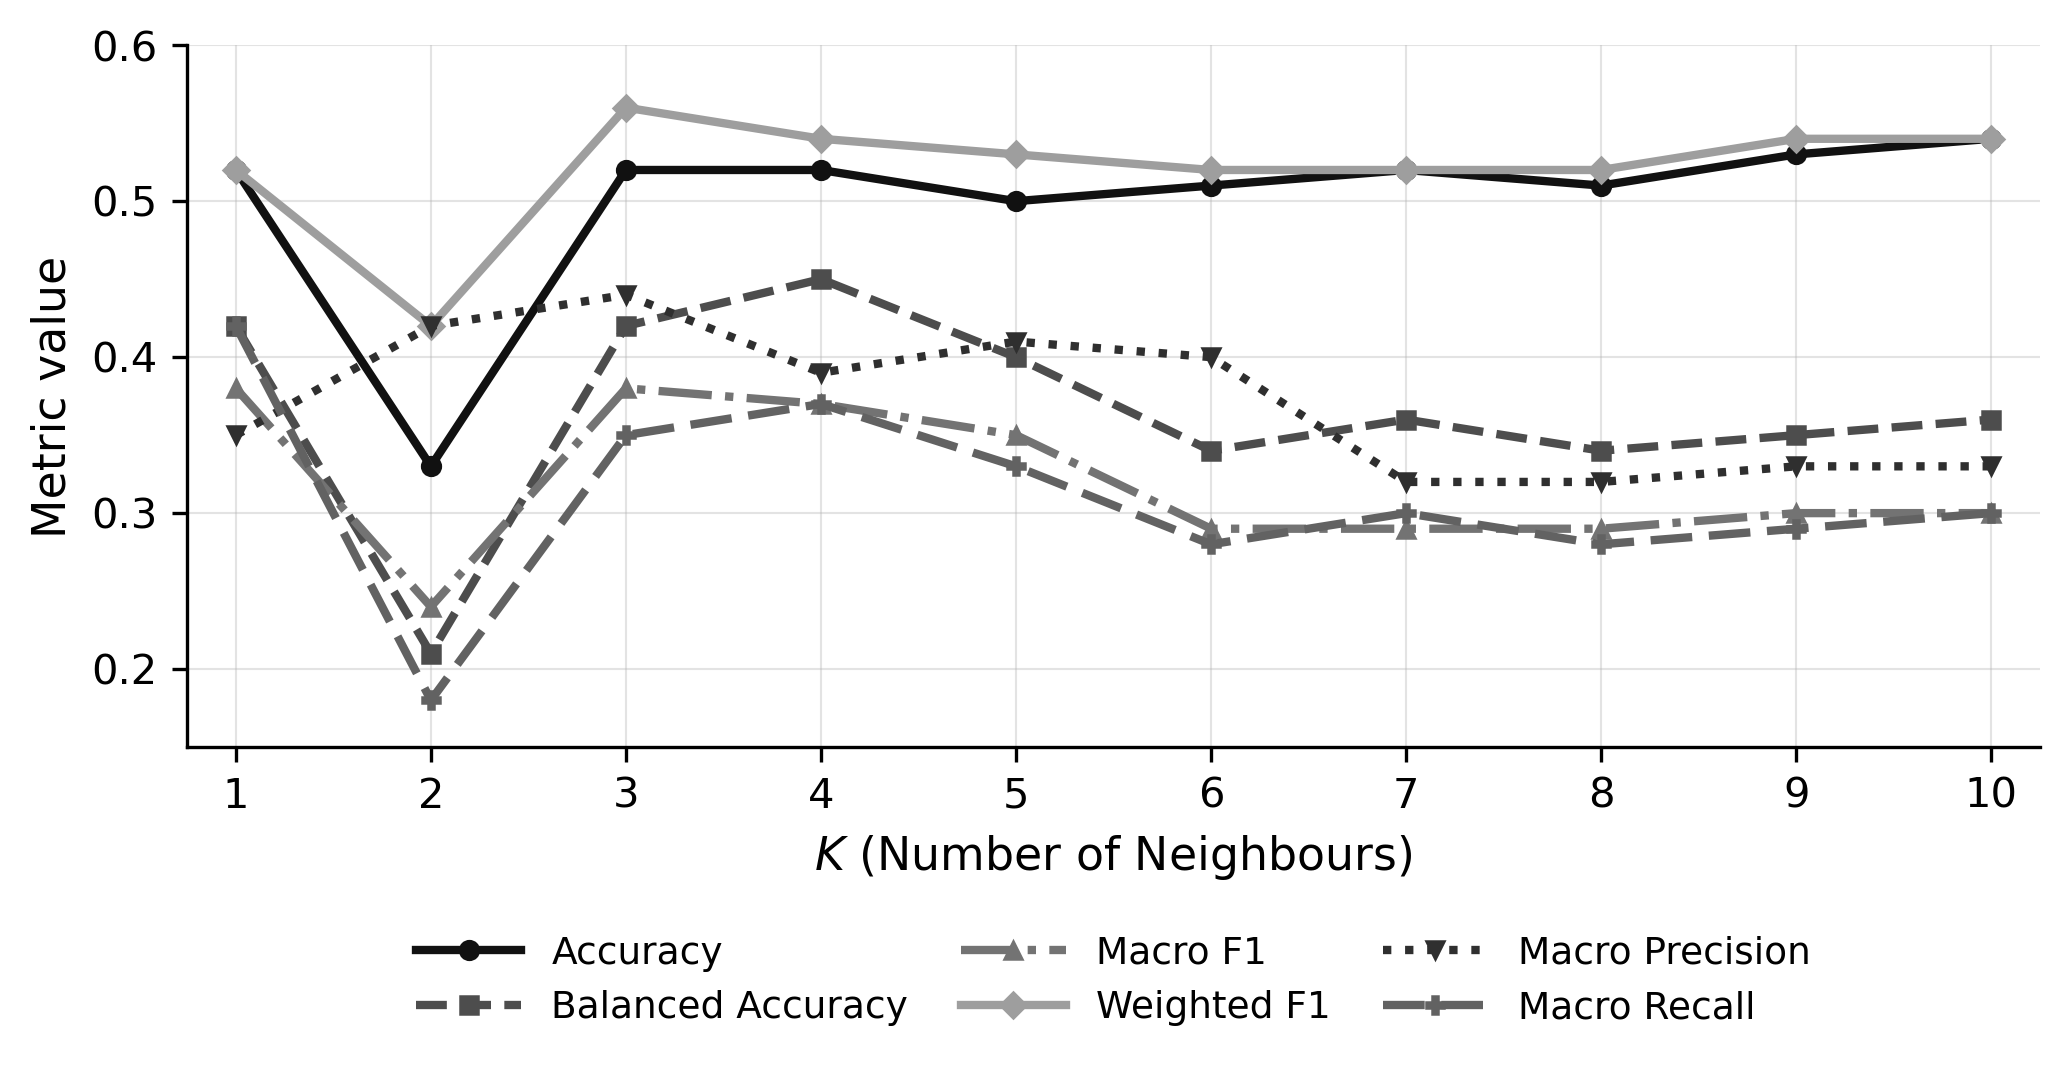

('fig5a_metric_values_by_k.png',
 'fig5a_metric_values_by_k.pdf',
 'fig5a_metric_values_by_k.svg')

In [114]:
import pandas as pd
import matplotlib.pyplot as plt

# Data from Fig. 5A table
df = pd.DataFrame({
"K": list(range(1, 11)),
"Accuracy": [0.52, 0.33, 0.52, 0.52, 0.50, 0.51, 0.52, 0.51, 0.53, 0.54],
"Balanced Accuracy": [0.42, 0.21, 0.42, 0.45, 0.40, 0.34, 0.36, 0.34, 0.35, 0.36],
"Macro F1": [0.38, 0.24, 0.38, 0.37, 0.35, 0.29, 0.29, 0.29, 0.30, 0.30],
"Weighted F1": [0.52, 0.42, 0.56, 0.54, 0.53, 0.52, 0.52, 0.52, 0.54, 0.54],
"Macro Precision": [0.35, 0.42, 0.44, 0.39, 0.41, 0.40, 0.32, 0.32, 0.33, 0.33],
"Macro Recall": [0.42, 0.18, 0.35, 0.37, 0.33, 0.28, 0.30, 0.28, 0.29, 0.30],
})

# Neutral grayscale palette + distinct markers/line styles.
# This keeps Panel A visually separate from the colored subtype lines in Panel B.
styles = {
"Accuracy":{"color": "#111111", "marker": "o", "linestyle": "-"},
"Balanced Accuracy": {"color": "#4D4D4D", "marker": "s", "linestyle": "--"},
"Macro F1": {"color": "#737373", "marker": "^", "linestyle": "-."},
"Weighted F1": {"color": "#9E9E9E", "marker": "D", "linestyle": "-"},
"Macro Precision": {"color": "#2F2F2F", "marker": "v", "linestyle": ":"},
"Macro Recall": {"color": "#626262", "marker": "P", "linestyle": (0, (5, 2))},
}

fig, ax = plt.subplots(figsize=(7.0, 3.8), dpi=300)

for metric, style in styles.items():
    ax.plot(
    df["K"],
    df[metric],
    label=metric,
    linewidth=2.0,
    markersize=4.5,
    markeredgewidth=0.6,
    **style
    )

# No title/caption here; the figure caption belongs below the full multi-panel figure.
ax.set_xlabel(r"$K$ (Number of Neighbours)", fontsize=11)
ax.set_ylabel("Metric value", fontsize=11)

ax.set_xlim(0.75, 10.25)
ax.set_ylim(0.15, 0.60)
ax.set_xticks(df["K"])
ax.set_yticks([0.20, 0.30, 0.40, 0.50, 0.60])

ax.grid(True, linewidth=0.5, alpha=0.35)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
loc="upper center",
bbox_to_anchor=(0.5, -0.22),
ncol=3,
frameon=False,
fontsize=9,
handlelength=2.8,
columnspacing=1.4
)

fig.tight_layout()

png_path = "fig5a_metric_values_by_k.png"
pdf_path = "fig5a_metric_values_by_k.pdf"
svg_path = "fig5a_metric_values_by_k.svg"

fig.savefig(png_path, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")
fig.savefig(svg_path, bbox_inches="tight")

plt.show()

png_path, pdf_path, svg_path